# Práctica 3


In [15]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Dispositivo: {device}")

Dispositivo: cuda


## Preparación de Datos

In [16]:

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])


train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Imágenes de entrenamiento: {len(train_dataset)}")
print(f"Imágenes de prueba: {len(test_dataset)}")

Imágenes de entrenamiento: 60000
Imágenes de prueba: 10000


## Definición de CNN

Usaremos tres arquitecturas diferentes
1. **CNN Simple**: Una capa convolucional, una de pooling y una capa lineal.
2. **CNN Media**: Dos capas convolucionales, pooling y Dropout para evitar el sobreajuste.
3. **CNN Avanzada**: Tres capas convolucionales con Batch Normalization y regularización.

In [17]:
class CNNSimple(nn.Module):
    def __init__(self):
        super(CNNSimple, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Linear(16 * 14 * 14, 10)

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        return self.classifier(x)

class CNNMedia(nn.Module):
    def __init__(self):
        super(CNNMedia, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        return self.classifier(x)

class CNNAvanzada(nn.Module):
    def __init__(self):
        super(CNNAvanzada, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(64 * 7 * 7, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        return self.classifier(x)

## Funciones de Entrenamiento y Evaluación

In [18]:
def train_model(model, train_loader, test_loader, epochs=5, lr=0.001):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    history = {'train_loss': [], 'test_loss': [], 'test_acc': []}

    for epoch in range(epochs):
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)

        epoch_loss = running_loss / len(train_loader.dataset)

        test_loss = 0.0
        correct = 0
        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                test_loss += loss.item() * images.size(0)
                _, preds = torch.max(outputs, 1)
                correct += torch.sum(preds == labels.data)

        epoch_test_loss = test_loss / len(test_loader.dataset)
        epoch_test_acc = correct.double().item() / len(test_loader.dataset) * 100

        history['train_loss'].append(epoch_loss)
        history['test_loss'].append(epoch_test_loss)
        history['test_acc'].append(epoch_test_acc)

        print(f"Época {epoch+1}/{epochs} | Loss Train: {epoch_loss:.4f} | Loss Test: {epoch_test_loss:.4f} | Acc Test: {epoch_test_acc:.2f}%")

    return history

## Entrenamiento de las 3 Configuraciones

In [19]:
epochs = 5

print("=== Entrenando CNN Simple ===")
model_simple = CNNSimple()
history_simple = train_model(model_simple, train_loader, test_loader, epochs=epochs)

print("\n=== Entrenando CNN Media ===")
model_media = CNNMedia()
history_media = train_model(model_media, train_loader, test_loader, epochs=epochs)

print("\n=== Entrenando CNN Avanzada ===")
model_avanzada = CNNAvanzada()
history_avanzada = train_model(model_avanzada, train_loader, test_loader, epochs=epochs)

=== Entrenando CNN Simple ===
Época 1/5 | Loss Train: 0.1830 | Loss Test: 0.0738 | Acc Test: 97.64%
Época 2/5 | Loss Train: 0.0689 | Loss Test: 0.0584 | Acc Test: 98.04%
Época 3/5 | Loss Train: 0.0522 | Loss Test: 0.0536 | Acc Test: 98.29%
Época 4/5 | Loss Train: 0.0427 | Loss Test: 0.0539 | Acc Test: 98.16%
Época 5/5 | Loss Train: 0.0367 | Loss Test: 0.0477 | Acc Test: 98.54%

=== Entrenando CNN Media ===
Época 1/5 | Loss Train: 0.1652 | Loss Test: 0.0638 | Acc Test: 97.88%
Época 2/5 | Loss Train: 0.0662 | Loss Test: 0.0474 | Acc Test: 98.48%
Época 3/5 | Loss Train: 0.0484 | Loss Test: 0.0457 | Acc Test: 98.56%
Época 4/5 | Loss Train: 0.0398 | Loss Test: 0.0422 | Acc Test: 98.62%
Época 5/5 | Loss Train: 0.0360 | Loss Test: 0.0399 | Acc Test: 98.77%

=== Entrenando CNN Avanzada ===
Época 1/5 | Loss Train: 0.1557 | Loss Test: 0.0599 | Acc Test: 98.33%
Época 2/5 | Loss Train: 0.0616 | Loss Test: 0.0601 | Acc Test: 98.08%
Época 3/5 | Loss Train: 0.0498 | Loss Test: 0.0477 | Acc Test: 98.4

##Comparativa Visual y Numérica

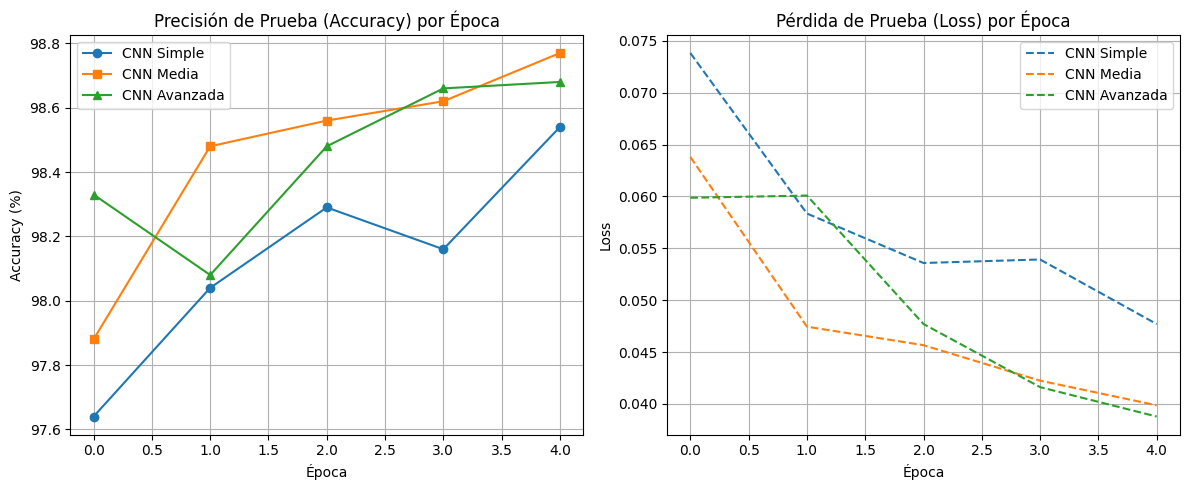

In [20]:
#(Accuracy)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_simple['test_acc'], label='CNN Simple', marker='o')
plt.plot(history_media['test_acc'], label='CNN Media', marker='s')
plt.plot(history_avanzada['test_acc'], label='CNN Avanzada', marker='^')
plt.title('Accuracy por Época')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss
plt.plot(history_simple['test_loss'], label='CNN Simple', linestyle='--')
plt.plot(history_media['test_loss'], label='CNN Media', linestyle='--')
plt.plot(history_avanzada['test_loss'], label='CNN Avanzada', linestyle='--')
plt.title('Loss por Época')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [21]:
# Tabla comparativa de resultados finales
resultados = {
    'Modelo': ['CNN Simple', 'CNN Media', 'CNN Avanzada'],
    'Pérdida Final (Test)': [
        history_simple['test_loss'][-1],
        history_media['test_loss'][-1],
        history_avanzada['test_loss'][-1]
    ],
    'Precisión Final (Test %)': [
        history_simple['test_acc'][-1],
        history_media['test_acc'][-1],
        history_avanzada['test_acc'][-1]
    ]
}

df_resultados = pd.DataFrame(resultados)
display(df_resultados)

,Modelo,Pérdida Final (Test),Precisión Final (Test %)
0,CNN Simple,0.047697,98.54
1,CNN Media,0.039865,98.77
2,CNN Avanzada,0.038780,98.68


##Guardar el Mejor Modelo en Disco

In [22]:
modelos = {
    'CNN Simple': (model_simple, history_simple['test_acc'][-1]),
    'CNN Media': (model_media, history_media['test_acc'][-1]),
    'CNN Avanzada': (model_avanzada, history_avanzada['test_acc'][-1])
}

mejor_nombre = max(modelos, key=lambda k: modelos[k][1])
mejor_modelo, mejor_acc = modelos[mejor_nombre]

print(f"El mejor modelo es: {mejor_nombre} con una precisión de {mejor_acc:.2f}%")


ruta_guardado = 'mejor_modelo_mnist.pth'
torch.save(mejor_modelo.state_dict(), ruta_guardado)
print(f"Modelo guardado con éxito en '{ruta_guardado}'")

El mejor modelo es: CNN Media con una precisión de 98.77%
Modelo guardado con éxito en 'mejor_modelo_mnist.pth'
